## Part II: compare embedding initialization

We use the LSTM for every Part II condition to hold architecture fixed and reuse the Part I random-embedding baseline. This is a considered compromise: among the recurrent models, the LSTM had better test perplexity than the RNN (350 vs. 360) and the highest neural inference throughput (20,747 tokens/s); the Transformer had better perplexity overall (295) but lower throughput (13,164 tokens/s). The assignment does not require the LSTM specifically. A Transformer embedding study would also be valid if all embedding variants, including its random-embedding baseline, used that same architecture.

This section compares the Part I LSTM with its jointly trained random input embeddings against two LSTMs whose 100-dimensional input embeddings are initialized from Skip-gram or GloVe and then frozen. Each run uses the same SentencePiece vocabulary, training data, context length, batch size, seed, and common test targets. Neural model training has a 25-epoch limit and stops after 5 consecutive epochs without validation-loss improvement.

- **Random, jointly learned baseline (requirement 1):** the Part I LSTM starts with PyTorch's randomly initialized input-embedding table and updates that table jointly with the LSTM during next-token training (`embedding_init` is empty and `freeze_embedding` is false in its saved config). The padding row is reserved as zero and receives no gradient; all lexical-token embedding rows are trainable. This is the random-initialization setting required by Part II.
- **Skip-gram:** vectors trained on the WikiText training token stream only, split at each `<eos>` so context windows do not cross source-line boundaries. `<pad>` is absent from the stream; `<eos>` remains as each sentence’s final token.
- **GloVe:** public Wiki-Gigaword vectors. GloVe is word-level while this project uses SentencePiece pieces, so only pieces that match a GloVe entry after removing SentencePiece’s word-start marker get pretrained vectors. Project special tokens are excluded from GloVe lookup; `<unk>` and GloVe `<eos>` use the mean matched lexical vector, and `<pad>` is zero. Other unmatched entries use seeded random values; lexical coverage is reported.

The random baseline updates its embeddings during language-model training, while the two pretrained tables are frozen. Interpret the comparison as a practical initialization-and-freezing comparison, not as a controlled test of embedding source alone. A single seed also means small differences should be treated cautiously.

In [3]:
from pathlib import Path
import json, subprocess, sys
import pandas as pd

# Works whether the notebook kernel starts in the project root or notebooks/.
ROOT = Path.cwd()
if not (ROOT / "src" / "train.py").exists():
    ROOT = ROOT.parent
assert (ROOT / "src" / "train.py").exists(), f"Could not locate project root from {Path.cwd()}"
DATA = ROOT / "data" / "processed_3m_max_tokens_30k_vocab"
RUNS = ROOT / "runs"
PART2_RUNS = RUNS / "part2_revised"
EMBEDDING_RUNS = RUNS / "embeddings"
RESULTS = ROOT / "results"

def run_live(command):
    """Run a project script and stream its progress into this notebook cell."""
    command = [str(part) for part in command]
    print("$", " ".join(command), flush=True)
    process = subprocess.Popen(command, cwd=ROOT, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in process.stdout:
        print(line, end="", flush=True)
    code = process.wait()
    if code:
        raise subprocess.CalledProcessError(code, command)

print("Project:", ROOT)
print("Data:", DATA)
print("Python:", sys.executable)

Project: /Users/paulng/Y4S1 Local files/DSA4213/dsa4213_oct13
Data: /Users/paulng/Y4S1 Local files/DSA4213/dsa4213_oct13/data/processed_3m_max_tokens_30k_vocab
Python: /Users/paulng/Y4S1 Local files/DSA4213/.venv313/bin/python


In [4]:
# Requirement 1: verify the Part I baseline used random initialization (no supplied matrix)
# and trained the table jointly (not frozen). It also shares the Part II LSTM settings.
baseline_config = json.loads((RUNS / "revised" / "lstm" / "config.json").read_text())
assert baseline_config["model"] == "lstm"
assert baseline_config["embedding_init"] == "" and not baseline_config["freeze_embedding"]
assert (baseline_config["emb"], baseline_config["hidden"], baseline_config["context"], baseline_config["batch_size"], baseline_config["seed"]) == (100, 128, 32, 32, 42)
# With no embedding_init, nn.Embedding is randomly initialized; freeze_embedding=False
# allows its non-padding rows to be learned with the language-model objective.
part1 = json.loads((RESULTS / "revised_common_evaluation.json").read_text())
baseline = part1["models"]["lstm"]
display(pd.DataFrame([{"embedding": "Random, jointly learned",
                      "test_loss": baseline["test_loss"],
                      "test_perplexity": baseline["test_ppl"],
                      "test_tokens": baseline["test_tokens"],
                      "training_seconds": baseline["training_seconds"]}]))

,embedding,test_loss,test_perplexity,test_tokens,training_seconds
0,"Random, jointly learned",5.857961,350.009842,272267,2413.23


### Run the Skip-gram variant

Run this cell to train 100-dimensional Skip-gram vectors on the WikiText training stream, initialize an LSTM from them, freeze the input embedding table, and evaluate that checkpoint on the common test targets. The cell streams epoch logs here. Set `RUN_SKIPGRAM` to `True` when you are ready, then run the cell.

In [5]:
RUN_SKIPGRAM = True
if RUN_SKIPGRAM:
    run_live([sys.executable, ROOT / "src" / "embeddings.py",
              "--method", "skipgram", "--data", DATA, "--out", EMBEDDING_RUNS,
              "--dim", "100", "--window", "5", "--epochs", "5", "--seed", "42"])
    skipgram_run = PART2_RUNS / "skipgram"
    run_live([sys.executable, ROOT / "src" / "train.py", "--model", "lstm",
              "--data", DATA, "--out", skipgram_run, "--epochs", "25", "--patience", "5",
              "--context", "32", "--batch-size", "32", "--seed", "42", "--device", "auto",
              "--embedding-init", EMBEDDING_RUNS / "skipgram_100d.npy", "--freeze-embedding"])
    run_live([sys.executable, ROOT / "src" / "evaluate_common.py", "--data", DATA,
              "--runs", skipgram_run, "--models", "lstm",
              "--out", RESULTS / "part2_skipgram.json"])


$ /Users/paulng/Y4S1 Local files/DSA4213/.venv313/bin/python /Users/paulng/Y4S1 Local files/DSA4213/dsa4213_oct13/src/embeddings.py --method skipgram --data /Users/paulng/Y4S1 Local files/DSA4213/dsa4213_oct13/data/processed_3m_max_tokens_30k_vocab --out /Users/paulng/Y4S1 Local files/DSA4213/dsa4213_oct13/runs/embeddings --dim 100 --window 5 --epochs 5 --seed 42
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.m

### Run the GloVe variant

This downloads GloVe Wiki-Gigaword 100-dimensional vectors the first time it runs, so it needs network access. The alignment code strips SentencePiece’s `▁` word-start marker before looking up a piece. Review the reported coverage: GloVe covers complete word pieces better than arbitrary subword fragments. Set `RUN_GLOVE` to `True` and run this cell when ready.

In [6]:
RUN_GLOVE = True
if RUN_GLOVE:
    run_live([sys.executable, ROOT / "src" / "embeddings.py",
              "--method", "glove", "--data", DATA, "--out", EMBEDDING_RUNS,
              "--dim", "100", "--seed", "42"])
    glove_run = PART2_RUNS / "glove"
    run_live([sys.executable, ROOT / "src" / "train.py", "--model", "lstm",
              "--data", DATA, "--out", glove_run, "--epochs", "25", "--patience", "5",
              "--context", "32", "--batch-size", "32", "--seed", "42", "--device", "auto",
              "--embedding-init", EMBEDDING_RUNS / "glove_100d.npy", "--freeze-embedding"])
    run_live([sys.executable, ROOT / "src" / "evaluate_common.py", "--data", DATA,
              "--runs", glove_run, "--models", "lstm",
              "--out", RESULTS / "part2_glove.json"])

$ /Users/paulng/Y4S1 Local files/DSA4213/.venv313/bin/python /Users/paulng/Y4S1 Local files/DSA4213/dsa4213_oct13/src/embeddings.py --method glove --data /Users/paulng/Y4S1 Local files/DSA4213/dsa4213_oct13/data/processed_3m_max_tokens_30k_vocab --out /Users/paulng/Y4S1 Local files/DSA4213/dsa4213_oct13/runs/embeddings --dim 100 --seed 42

[--------------------------------------------------] 0.0% 0.0/128.1MB downloaded
[--------------------------------------------------] 0.0% 0.0/128.1MB downloaded
[--------------------------------------------------] 0.0% 0.0/128.1MB downloaded
[--------------------------------------------------] 0.0% 0.0/128.1MB downloaded
[--------------------------------------------------] 0.0% 0.0/128.1MB downloaded
[--------------------------------------------------] 0.0% 0.0/128.1MB downloaded
[--------------------------------------------------] 0.0% 0.0/128.1MB downloaded
[--------------------------------------------------] 0.0% 0.1/128.1MB downloaded
[---------

In [7]:
# Rerun this after Skip-gram and/or GloVe evaluations exist.
comparison = [{"embedding": "Random, jointly learned",
               "test_loss": baseline["test_loss"], "test_perplexity": baseline["test_ppl"],
               "test_tokens": baseline["test_tokens"], "training_seconds": baseline["training_seconds"]}]
for method in ("skipgram", "glove"):
    path = RESULTS / f"part2_{method}.json"
    if path.exists():
        result = json.loads(path.read_text())["models"]["lstm"]
        comparison.append({"embedding": method.title() + ", frozen",
                           "test_loss": result["test_loss"], "test_perplexity": result["test_ppl"],
                           "test_tokens": result["test_tokens"], "training_seconds": result["training_seconds"]})
display(pd.DataFrame(comparison).set_index("embedding").round(4))

,test_loss,test_perplexity,test_tokens,training_seconds
embedding,,,,
"Random, jointly learned",5.8580,350.0098,272267,2413.23
"Skipgram, frozen",5.7166,303.8782,272267,3473.09
"Glove, frozen",5.8064,332.4318,272267,2843.79


### Part II results and interpretation

The three LSTM conditions use 100-dimensional input embeddings and were evaluated on the same 272,267 test targets. The Part I random-embedding LSTM is the jointly learned baseline.

| Embedding condition | Test cross-entropy (nats/token) | Test perplexity | Vocabulary type coverage | Best validation epoch | Early stop epoch |
|---|---:|---:|---:|---:|---:|
| Random, jointly learned | 5.858 | 350.0 | N/A | 7 | 12 |
| Skip-gram, frozen | **5.717** | **303.9** | 93.8% | 12 | 17 |
| GloVe, frozen | 5.806 | 332.4 | 81.8% | 10 | 15 |

On this test set, Skip-gram performed best: its loss was about 2.4% lower and its perplexity about 13.2% lower than the random baseline. GloVe also improved on the random baseline, by about 0.9% in loss and 5.0% in perplexity, but did not match Skip-gram. These are observed results from one seed, not evidence that the embedding method alone caused the ranking.

Skip-gram was trained on this project’s training stream and covered 93.8% of the non-special vocabulary by type; GloVe covered 81.8%. A plausible explanation for Skip-gram’s advantage is its better match to the project’s SentencePiece vocabulary and corpus. GloVe is word-level, so unmatched pieces received fallback vectors that remained frozen. Although public GloVe supplies additional pretraining data, that did not yield the best result here. The frozen tables also could not adapt their vectors to the next-token objective. These explanations are hypotheses; the experiment does not isolate them.

Validation loss reached its minimum at epoch 12 for Skip-gram and epoch 10 for GloVe, after which training loss kept falling while validation loss rose; early stopping selected those best-validation checkpoints. The random baseline reached its best validation loss at epoch 7 and stopped at epoch 12. This pattern is consistent with overfitting after the validation minimum.

The language-model training costs were 2,413.23 s for random, 3,473.09 s for Skip-gram, and 2,843.79 s for GloVe. Skip-gram embedding training adds a separate 48.01 s (five epochs; project-side total 3,521.10 s). GloVe download/load and alignment add 42.33 s (project-side total 2,886.12 s); its public pretraining cost is unmeasured and excluded. The public vectors were trained using Wikipedia 2014 and Gigaword 5, about 6 billion tokens and 400,000 word types.

The random embedding table is trainable with the LSTM; Skip-gram and GloVe tables are fully frozen. Both fixed conditions beat random on test perplexity, suggesting that their pretrained signal helped here despite being unable to adapt to the next-token objective. Skip-gram performed best, plausibly because it was trained on the same corpus and had higher type coverage (93.8% vs. GloVe’s 81.8%). GloVe contributes much more external text, but its word-level vectors miss more SentencePiece pieces. Source and trainability are confounded in this comparison, so these are possible explanations rather than causal findings.

Within-run convergence is smooth early on. Validation minima occur at epoch 7 for random (5.857), epoch 12 for Skip-gram (5.759), and epoch 10 for GloVe (5.825); patience stopping ends the runs at epochs 12, 17, and 15. Training loss continues to fall after the validation minima, while validation loss rises modestly. Train–validation gaps grow from 0.728/0.764/0.706 at the selected checkpoints to 1.175/0.955/0.929 at the final epochs. The plot below shows no abrupt loss spikes, though validation loss fluctuates around its minimum. This is within-run stability only; one seed per condition cannot measure run-to-run variation.

Matched generations use the same prompts and decoding settings (Appendix C). For “The government announced,” random starts “that the ‘big boy’...” and drifts; Skip-gram continues “the first nations for the british government...” with repetition; GloVe stops after “that the ‘never ever in’.” The samples illustrate that Skip-gram’s better perplexity does not guarantee coherent continuation. This small sample is qualitative, not a fluency ranking.

#### Part II convergence and training stability

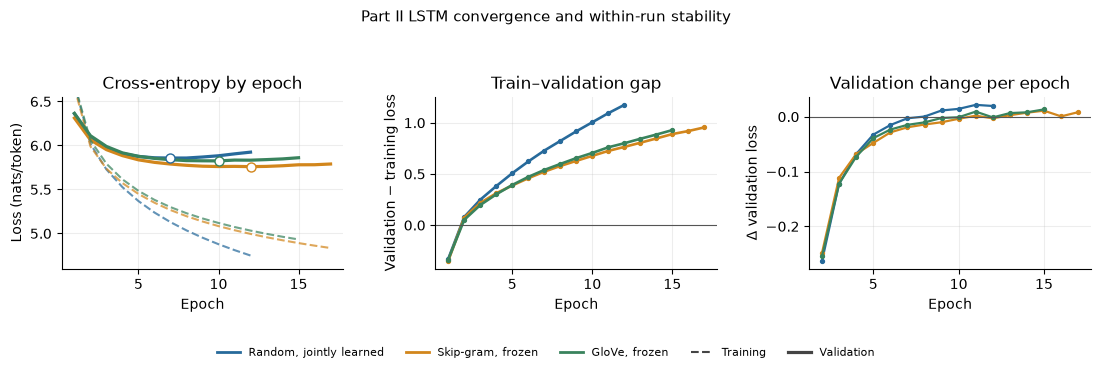

In [4]:
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.lines import Line2D

histories = {
    "Random, jointly learned": RUNS / "revised" / "lstm" / "history.csv",
    "Skip-gram, frozen": PART2_RUNS / "skipgram" / "lstm" / "history.csv",
    "GloVe, frozen": PART2_RUNS / "glove" / "lstm" / "history.csv",
}
colors = {"Random, jointly learned": "#276A9B", "Skip-gram, frozen": "#D2861C", "GloVe, frozen": "#39835D"}
fig, axes = plt.subplots(1, 3, figsize=(11.2, 3.45))
loss_ax, gap_ax, delta_ax = axes
for name, path in histories.items():
    history = pd.read_csv(path)
    history["gap"] = history["val_loss"] - history["train_loss"]
    history["delta_val"] = history["val_loss"].diff()
    color = colors[name]
    loss_ax.plot(history.epoch, history.train_loss, color=color, lw=1.5, ls="--", alpha=.72)
    loss_ax.plot(history.epoch, history.val_loss, color=color, lw=2.3)
    best = history.loc[history.val_loss.idxmin()]
    loss_ax.scatter([best.epoch], [best.val_loss], s=42, facecolor="white", edgecolor=color, zorder=5)
    gap_ax.plot(history.epoch, history.gap, color=color, marker="o", ms=2.8, lw=1.9)
    delta_ax.plot(history.epoch.iloc[1:], history.delta_val.iloc[1:], color=color, marker="o", ms=2.8, lw=1.6)
for ax, title, ylabel in zip(axes, ["Cross-entropy by epoch", "Train–validation gap", "Validation change per epoch"], ["Loss (nats/token)", "Validation − training loss", "Δ validation loss"]):
    ax.set(title=title, xlabel="Epoch", ylabel=ylabel)
    ax.grid(True, alpha=.22)
    ax.spines[["top", "right"]].set_visible(False)
loss_ax.set_ylim(4.6, 6.55)
gap_ax.axhline(0, color="#555", lw=.8)
delta_ax.axhline(0, color="#555", lw=.8)
legend = [Line2D([0], [0], color=colors[n], lw=2, label=n) for n in histories]
legend += [Line2D([0], [0], color="#444", ls="--", lw=1.5, label="Training"), Line2D([0], [0], color="#444", lw=2.3, label="Validation")]
fig.legend(handles=legend, loc="lower center", ncol=5, frameon=False, bbox_to_anchor=(.5, -.02), fontsize=8)
fig.suptitle("Part II LSTM convergence and within-run stability", fontsize=11, y=1.02)
fig.tight_layout(rect=(0, .10, 1, .96), w_pad=1.4)
fig.savefig(RESULTS / "part2_convergence_stability.png", dpi=220, bbox_inches="tight")
display(fig)
plt.close(fig)

Dashed curves are training loss; bold curves are validation loss. Open circles mark each minimum validation loss. The center panel shows the train–validation gap; the right panel shows epoch-to-epoch validation-loss changes. The figure describes these saved runs and does not estimate variation across seeds.

### Part II: matched generated continuations

The following saved generations use the same prompts and sampling settings for the Part I random-trained LSTM and the two frozen-embedding LSTMs. Set `RUN_PART_II_GENERATION = True` to regenerate them from the saved checkpoints; otherwise the cell displays `results/part2_generation.json`.

In [ ]:
# Regenerate only when you want fresh samples; otherwise display the saved matched run.
RUN_PART_II_GENERATION = False
if RUN_PART_II_GENERATION:
    run_live([sys.executable, ROOT / "src" / "generate_embedding_compare.py",
              "--data", DATA, "--runs", ROOT,
              "--out", RESULTS / "part2_generation.json",
              "--new-tokens", "30", "--temperature", "0.8", "--top-k", "40", "--seed", "42"])

part2_generation = json.loads((RESULTS / "part2_generation.json").read_text())
for condition, result in part2_generation["conditions"].items():
    print(f"\n{result['description']}")
    for sample in result["samples"]:
        ending = f" [stopped at <eos> after {sample['generated_tokens']} pieces]" if sample["stopped_at_eos"] else " [30-piece limit]"
        print(f"\nPrompt: {sample['prompt']}\nContinuation: {sample['continuation']}{ending}")


Part I LSTM; random input embeddings learned jointly

Prompt: The scientist studied
Continuation: at the age of the country . " [stopped at <eos> after 8 pieces]

Prompt: The government announced
Continuation: that the " big boy " is a part of all time of the season , and has been known as their ownisation — the first person . [stopped at <eos> after 29 pieces]

Prompt: In the history of
Continuation: the film . these were recorded , and that he does not believe her with a limited edition of the song as a song . [stopped at <eos> after 25 pieces]

LSTM; corpus-trained Skip-gram input embeddings frozen

Prompt: The scientist studied
Continuation: that " some people of scientology were told in the early 1819 to this " , " a lot of being " too successful for the song , " as [30-piece limit]

Prompt: The government announced
Continuation: that the first nations for the british government in the federal government , and the first time since they had been scheduled to purchase funds , and t

## Part III: downstream representations

Compare frozen Part I LSTM and Transformer representations on AG News topic classification. The script mean-pools valid contextual states and fits the same standardized logistic-regression classifier for both encoders. AG News downloads the first time this section runs.

In [9]:
RUN_PART_III = True
if RUN_PART_III:
    run_live([sys.executable, ROOT / "src" / "downstream.py",
              "--data", DATA, "--runs", RUNS / "revised",
              "--out", RUNS / "downstream_revised", "--train-limit", "20000",
              "--max-len", "128", "--seed", "42", "--device", "auto"])

$ /Users/paulng/Y4S1 Local files/DSA4213/.venv313/bin/python /Users/paulng/Y4S1 Local files/DSA4213/dsa4213_oct13/src/downstream.py --data /Users/paulng/Y4S1 Local files/DSA4213/dsa4213_oct13/data/processed_3m_max_tokens_30k_vocab --runs /Users/paulng/Y4S1 Local files/DSA4213/dsa4213_oct13/runs/revised --out /Users/paulng/Y4S1 Local files/DSA4213/dsa4213_oct13/runs/downstream_revised --train-limit 20000 --max-len 128 --seed 42 --device auto

Generating train split: 100%|██████████| 120000/120000 [00:00<00:00, 1968502.18 examples/s]

Generating test split: 100%|██████████| 7600/7600 [00:00<00:00, 2326088.03 examples/s]
lstm 0.6118421052631579 0.6105049948719776
transformer 0.6917105263157894 0.6905793323664333
{
  "dataset": "AG News",
  "classes": [
    "World",
    "Sports",
    "Business",
    "Sci/Tech"
  ],
  "train_examples": 20000,
  "test_examples": 7600,
  "train_limit": 20000,
  "max_tokens": 128,
  "representation": "mean of valid contextual hidden states; frozen language mod

In [6]:
downstream_path = RUNS / "downstream_revised" / "results.json"
if downstream_path.exists():
    downstream = json.loads(downstream_path.read_text())
    display(pd.DataFrame(downstream["models"]).T[["accuracy", "macro_f1", "errors", "train_unk_rate", "test_unk_rate"]])
else:
    print("Run the Part III cell above to create the downstream results.")

,accuracy,macro_f1,errors,train_unk_rate,test_unk_rate
lstm,0.611842,0.610505,2950,0.0,0.0
transformer,0.691711,0.690579,2343,0.0,0.0


In [17]:
import pandas as pd

# Extract classification reports for each model
classification_reports = {}
for model_name, model_data in downstream["models"].items():
    if "classification_report" in model_data:
        classification_reports[model_name] = model_data["classification_report"]
# print(pd.DataFrame(classification_reports))

# Convert each classification report into a DataFrame and display
for model_name, report in classification_reports.items():
    print(f"Classification Report for {model_name.capitalize()} Model:")
    report_df = pd.DataFrame(report).T

    # Map indices to class names
    class_names = downstream["classes"]
    report_df.index = [class_names[int(idx)] if idx.isdigit() else idx for idx in report_df.index]

    # Display the updated DataFrame
    display(report_df)

Classification Report for Lstm Model:


,precision,recall,f1-score,support
World,0.609343,0.624737,0.616944,1900.000000
Sports,0.680494,0.725263,0.702166,1900.000000
Business,0.581028,0.541579,0.560610,1900.000000
Sci/Tech,0.568966,0.555789,0.562300,1900.000000
accuracy,0.611842,0.611842,0.611842,0.611842
macro avg,0.609957,0.611842,0.610505,7600.000000
weighted avg,0.609957,0.611842,0.610505,7600.000000


Classification Report for Transformer Model:


,precision,recall,f1-score,support
World,0.684184,0.712632,0.698118,1900.000000
Sports,0.793634,0.813684,0.803534,1900.000000
Business,0.622185,0.581579,0.601197,1900.000000
Sci/Tech,0.659989,0.658947,0.659468,1900.000000
accuracy,0.691711,0.691711,0.691711,0.691711
macro avg,0.689998,0.691711,0.690579,7600.000000
weighted avg,0.689998,0.691711,0.690579,7600.000000


### Part III interpretation

Each AG News article was tokenized with the project SentencePiece tokenizer and truncated to 128 tokens. The frozen LSTM or Transformer produced a contextual state for each token; averaging the valid states while excluding padding gave one 128-dimensional article vector. The same StandardScaler plus multinomial logistic-regression classifier was trained on 20,000 labeled training articles and evaluated on the 7,600 held-out test articles. Only the classifiers were trained.

| Representation | Test accuracy | Test macro-F1 | Test errors |
|---|---:|---:|---:|
| LSTM mean-pooled states | 61.18% | 61.05% | 2,950 / 7,600 |
| Transformer mean-pooled states | **69.17%** | **69.06%** | **2,343 / 7,600** |

The Transformer representation performed better by about 8.0 percentage points in both accuracy and macro-F1, with 607 fewer test errors. The error examples show a shared difficulty with overlapping topics: both models classified a Sci/Tech article about a company grant to study peptides as World. The LSTM also labeled a Business pension article as Sports, while the Transformer labeled it World. The Transformer improved the aggregate results, but these examples show that mean-pooled features and a linear classifier still miss some article-level distinctions.

This downstream ranking agrees with Part I: the Transformer had lower next-token perplexity than the LSTM (294.6 versus 350.0) and also scored higher on AG News. This is an observation from these two trained models and this one classification setup; it does not establish that lower language-model perplexity generally guarantees better classification.

In [35]:
import pandas as pd
pd.set_option('display.max_colwidth', None)  # Set to display full text

# Load error examples for LSTM and Transformer
lstm_errors_path = RUNS / "downstream_revised" / "lstm_errors.csv"
transformer_errors_path = RUNS / "downstream_revised" / "transformer_errors.csv"

if lstm_errors_path.exists() and transformer_errors_path.exists():
    lstm_errors = pd.read_csv(lstm_errors_path)
    transformer_errors = pd.read_csv(transformer_errors_path)
    # Map indices to class names
    lstm_errors['gold']= [class_names[int(idx)] if isinstance(idx,int) else idx for idx in lstm_errors["gold"]]
    lstm_errors['predicted']= [class_names[int(idx)] if isinstance(idx,int) else idx for idx in lstm_errors["predicted"]]
    transformer_errors['gold']= [class_names[int(idx)] if isinstance(idx,int) else idx for idx in transformer_errors["gold"]]
    transformer_errors['predicted']= [class_names[int(idx)] if isinstance(idx,int) else idx for idx in transformer_errors["predicted"]]
    # Display a few representative errors from each
    print("Representative LSTM Errors:")
    display(lstm_errors.head(5))  # Display 5 random errors from LSTM
    
    print("\nRepresentative Transformer Errors:")
    display(transformer_errors.head(5))  # Display 5 random errors from Transformer
else:
    print("Error files not found. Ensure the downstream evaluation has been run.")


Representative LSTM Errors:


,text,gold,predicted
0,Fears for T N pension after talks Unions representing workers at Turner Newall say they are 'disappointed' after talks with stricken parent firm Federal Mogul.,Business,Sports
1,"Ky. Company Wins Grant to Study Peptides (AP) AP - A company founded by a chemistry researcher at the University of Louisville won a grant to develop a method of producing better peptides, which are short chains of amino acids, the building blocks of proteins.",Sci/Tech,World
2,"Open Letter Against British Copyright Indoctrination in Schools The British Department for Education and Skills (DfES) recently launched a ""Music Manifesto"" campaign, with the ostensible intention of educating the next generation of British musicians. Unfortunately, they also teamed up with the music industry (EMI, and various artists) to make this popular. EMI has apparently negotiated their end well, so that children in our schools will now be indoctrinated about the illegality of downloading music.The ignorance and audacity of this got to me a little, so I wrote an open letter to the DfES about it. Unfortunately, it's pedantic, as I suppose you have to be when writing to goverment representatives. But I hope you find it useful, and perhaps feel inspired to do something similar, if or when the same thing has happened in your area.",Sci/Tech,World
3,"Group to Propose New High-Speed Wireless Format LOS ANGELES (Reuters) - A group of technology companies including Texas Instruments Inc. &lt;TXN.N&gt;, STMicroelectronics &lt;STM.PA&gt; and Broadcom Corp. &lt;BRCM.O&gt;, on Thursday said they will propose a new wireless networking standard up to 10 times the speed of the current generation.",Sci/Tech,Business
4,"Super ant colony hits Australia A giant 100km colony of ants which has been discovered in Melbourne, Australia, could threaten local insect species.",Sci/Tech,Business



Representative Transformer Errors:


,text,gold,predicted
0,Fears for T N pension after talks Unions representing workers at Turner Newall say they are 'disappointed' after talks with stricken parent firm Federal Mogul.,Business,World
1,"Ky. Company Wins Grant to Study Peptides (AP) AP - A company founded by a chemistry researcher at the University of Louisville won a grant to develop a method of producing better peptides, which are short chains of amino acids, the building blocks of proteins.",Sci/Tech,World
2,"Prediction Unit Helps Forecast Wildfires (AP) AP - It's barely dawn when Mike Fitzpatrick starts his shift with a blur of colorful maps, figures and endless charts, but already he knows what the day will bring. Lightning will strike in places he expects. Winds will pick up, moist places will dry and flames will roar.",Sci/Tech,Sports
3,"Calif. Aims to Limit Farm-Related Smog (AP) AP - Southern California's smog-fighting agency went after emissions of the bovine variety Friday, adopting the nation's first rules to reduce air pollution from dairy cow manure.",Sci/Tech,Business
4,"Open Letter Against British Copyright Indoctrination in Schools The British Department for Education and Skills (DfES) recently launched a ""Music Manifesto"" campaign, with the ostensible intention of educating the next generation of British musicians. Unfortunately, they also teamed up with the music industry (EMI, and various artists) to make this popular. EMI has apparently negotiated their end well, so that children in our schools will now be indoctrinated about the illegality of downloading music.The ignorance and audacity of this got to me a little, so I wrote an open letter to the DfES about it. Unfortunately, it's pedantic, as I suppose you have to be when writing to goverment representatives. But I hope you find it useful, and perhaps feel inspired to do something similar, if or when the same thing has happened in your area.",Sci/Tech,World
